##**Лабораторная работа №4 Обработка рентгеновских снимков багажа**
### **Работу выполнила студентка 2 курса магистратуры группы КомЗр24 Бобина Татьяна Сергеевна**

##Задание 1
Ознакомиться с датасетом https://universe.roboflow.com/malek-mhnrl/x-ray-baggage-detection/dataset/1

Выполнить визуализации, вывести пример разметки, загрузить разметку в формате YOLOv8

In [8]:
import zipfile
import os
import yaml
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np

# Распаковка архива
with zipfile.ZipFile('/content/X-ray baggage detection.v1-prohibited_items.yolov8.zip', 'r') as zip_ref:
    zip_ref.extractall('xray_dataset')

# Анализ структуры датасета
dataset_path = 'xray_dataset'
print("Содержимое датасета:")
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 2 * (level + 1)
    for file in files[:5]:
        print(f"{subindent}{file}")

# Загрузка конфигурации датасета
with open(os.path.join(dataset_path, 'data.yaml'), 'r') as f:
    data_config = yaml.safe_load(f)

print(f"\nКлассы: {data_config['names']}")
print(f"Количество классов: {data_config['nc']}")

Содержимое датасета:
xray_dataset/
  data.yaml
  README.dataset.txt
  README.roboflow.txt
  valid/
    labels/
      026839_jpg.rf.fd1d1503d157a2329111ff9d94de6126.txt
      037442_jpg.rf.ea262e4c0c227a99306cbb24db070204.txt
      027263_jpg.rf.9f85124beaee5a44a05cf94474556a30.txt
      017420_jpg.rf.6e4b0184810cb4b9fe55e49002ec22ee.txt
      041515_jpg.rf.f66da4a28fc02508998c2d6c539fecad.txt
    images/
      041418_jpg.rf.347dc11a587ca2af2377df6a6b756a0f.jpg
      037245_jpg.rf.399bf2aefa344536630ea9f0a6a5f6be.jpg
      031107_jpg.rf.ea07bf1cefa78f676521e33d5a9efed0.jpg
      035028_jpg.rf.b9502872e9d5d1b12b7fa991e285e23c.jpg
      010083_jpg.rf.c3fbd71a8d001568a2dace79d65ed93a.jpg
  train/
    labels/
      025024_jpg.rf.72d8db86411c5868a966d29b020ed771.txt
      039303_jpg.rf.bf6fe3f30a098ca76e30ce5e4cc6fbab.txt
      009287_jpg.rf.26057e69a04325fa113878d82ce3838d.txt
      036411_jpg.rf.e54ca3d5b1d1d486e8f37df29b725e8c.txt
      032325_jpg.rf.271575d55e481bfdd181ea7f31128a44.txt
 

Классы: ['0', '1', '2', '3', '4']
Количество классов: 5

TRAIN:
  Изображений: 6181
  Файлов разметки: 6181
  Всего объектов: 6181
  Распределение по классам:
     Класс 0: 1284 объектов ( 20.8%)
     Класс 1: 1393 объектов ( 22.5%)
     Класс 2:  698 объектов ( 11.3%)
     Класс 3: 1379 объектов ( 22.3%)
     Класс 4: 1427 объектов ( 23.1%)

VALID:
  Изображений: 1766
  Файлов разметки: 1766
  Всего объектов: 1766
  Распределение по классам:
     Класс 0:  391 объектов ( 22.1%)
     Класс 1:  389 объектов ( 22.0%)
     Класс 2:  225 объектов ( 12.7%)
     Класс 3:  366 объектов ( 20.7%)
     Класс 4:  395 объектов ( 22.4%)

TEST:
  Изображений: 883
  Файлов разметки: 883
  Всего объектов: 883
  Распределение по классам:
     Класс 0:  166 объектов ( 18.8%)
     Класс 1:  193 объектов ( 21.9%)
     Класс 2:  118 объектов ( 13.4%)
     Класс 3:  203 объектов ( 23.0%)
     Класс 4:  203 объектов ( 23.0%)
ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ С РАЗМЕТКОЙ - 6 ИЗОБРАЖЕНИЙ


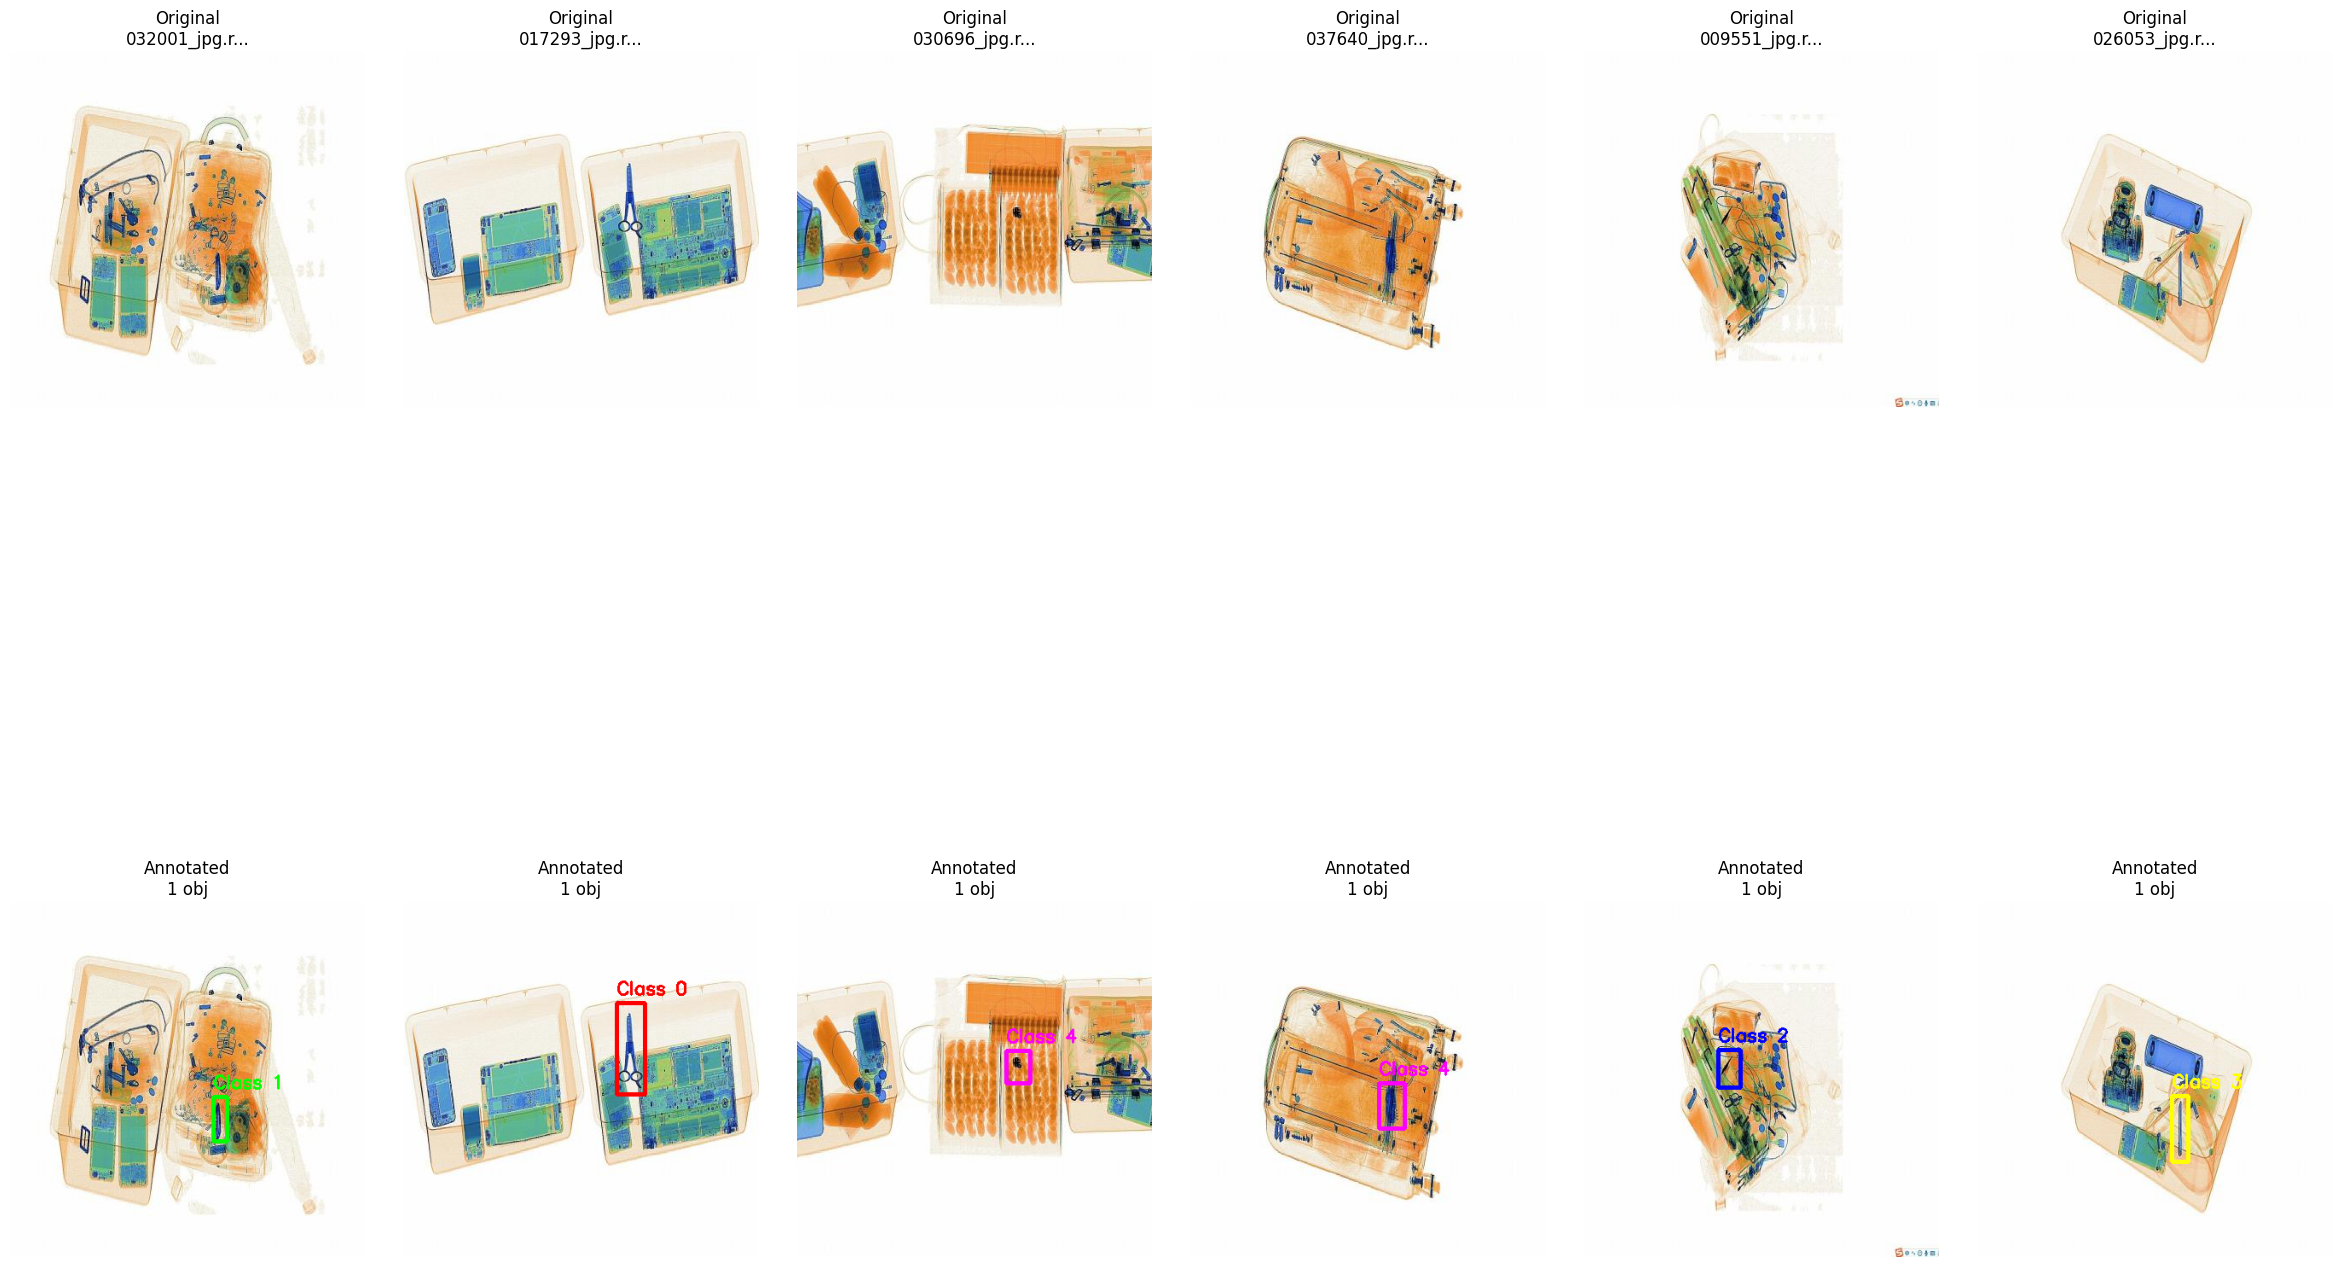

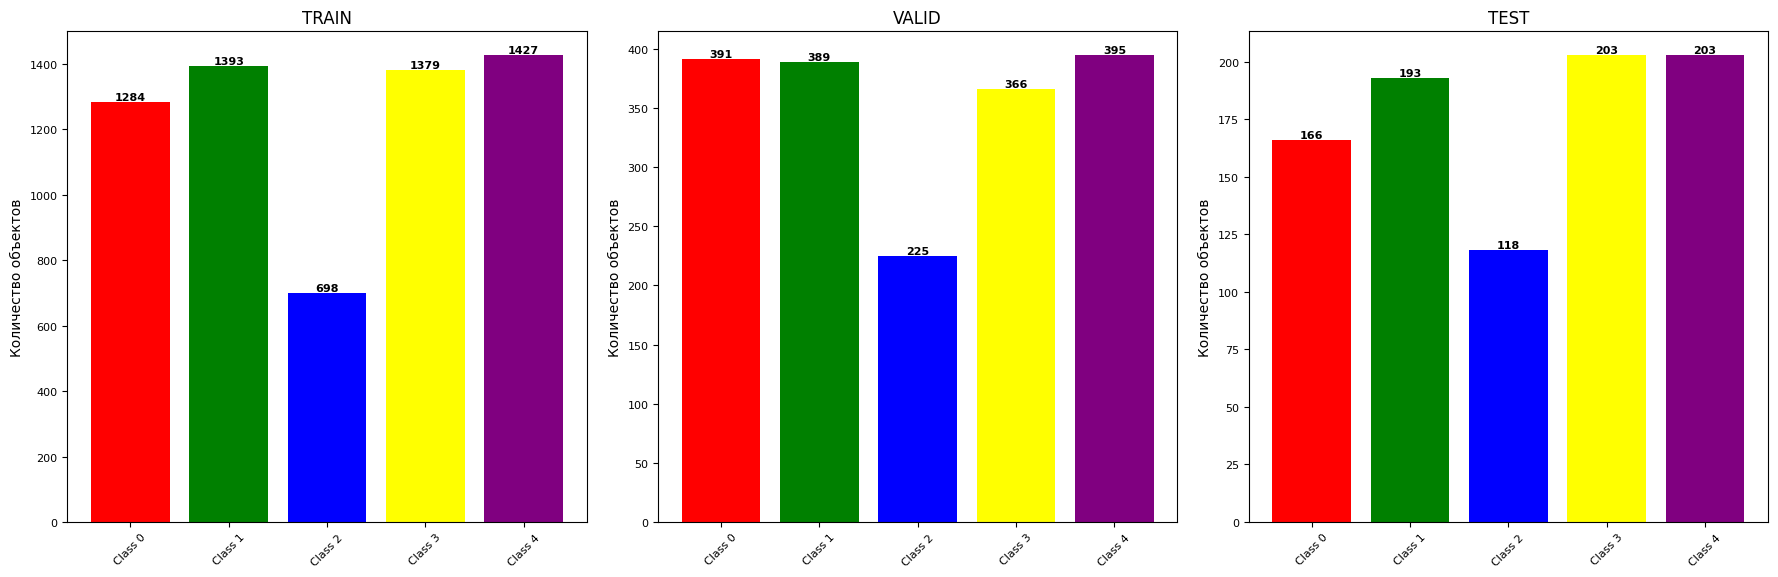

ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ ИЗ VALIDATION SET - 4 ИЗОБРАЖЕНИЯ


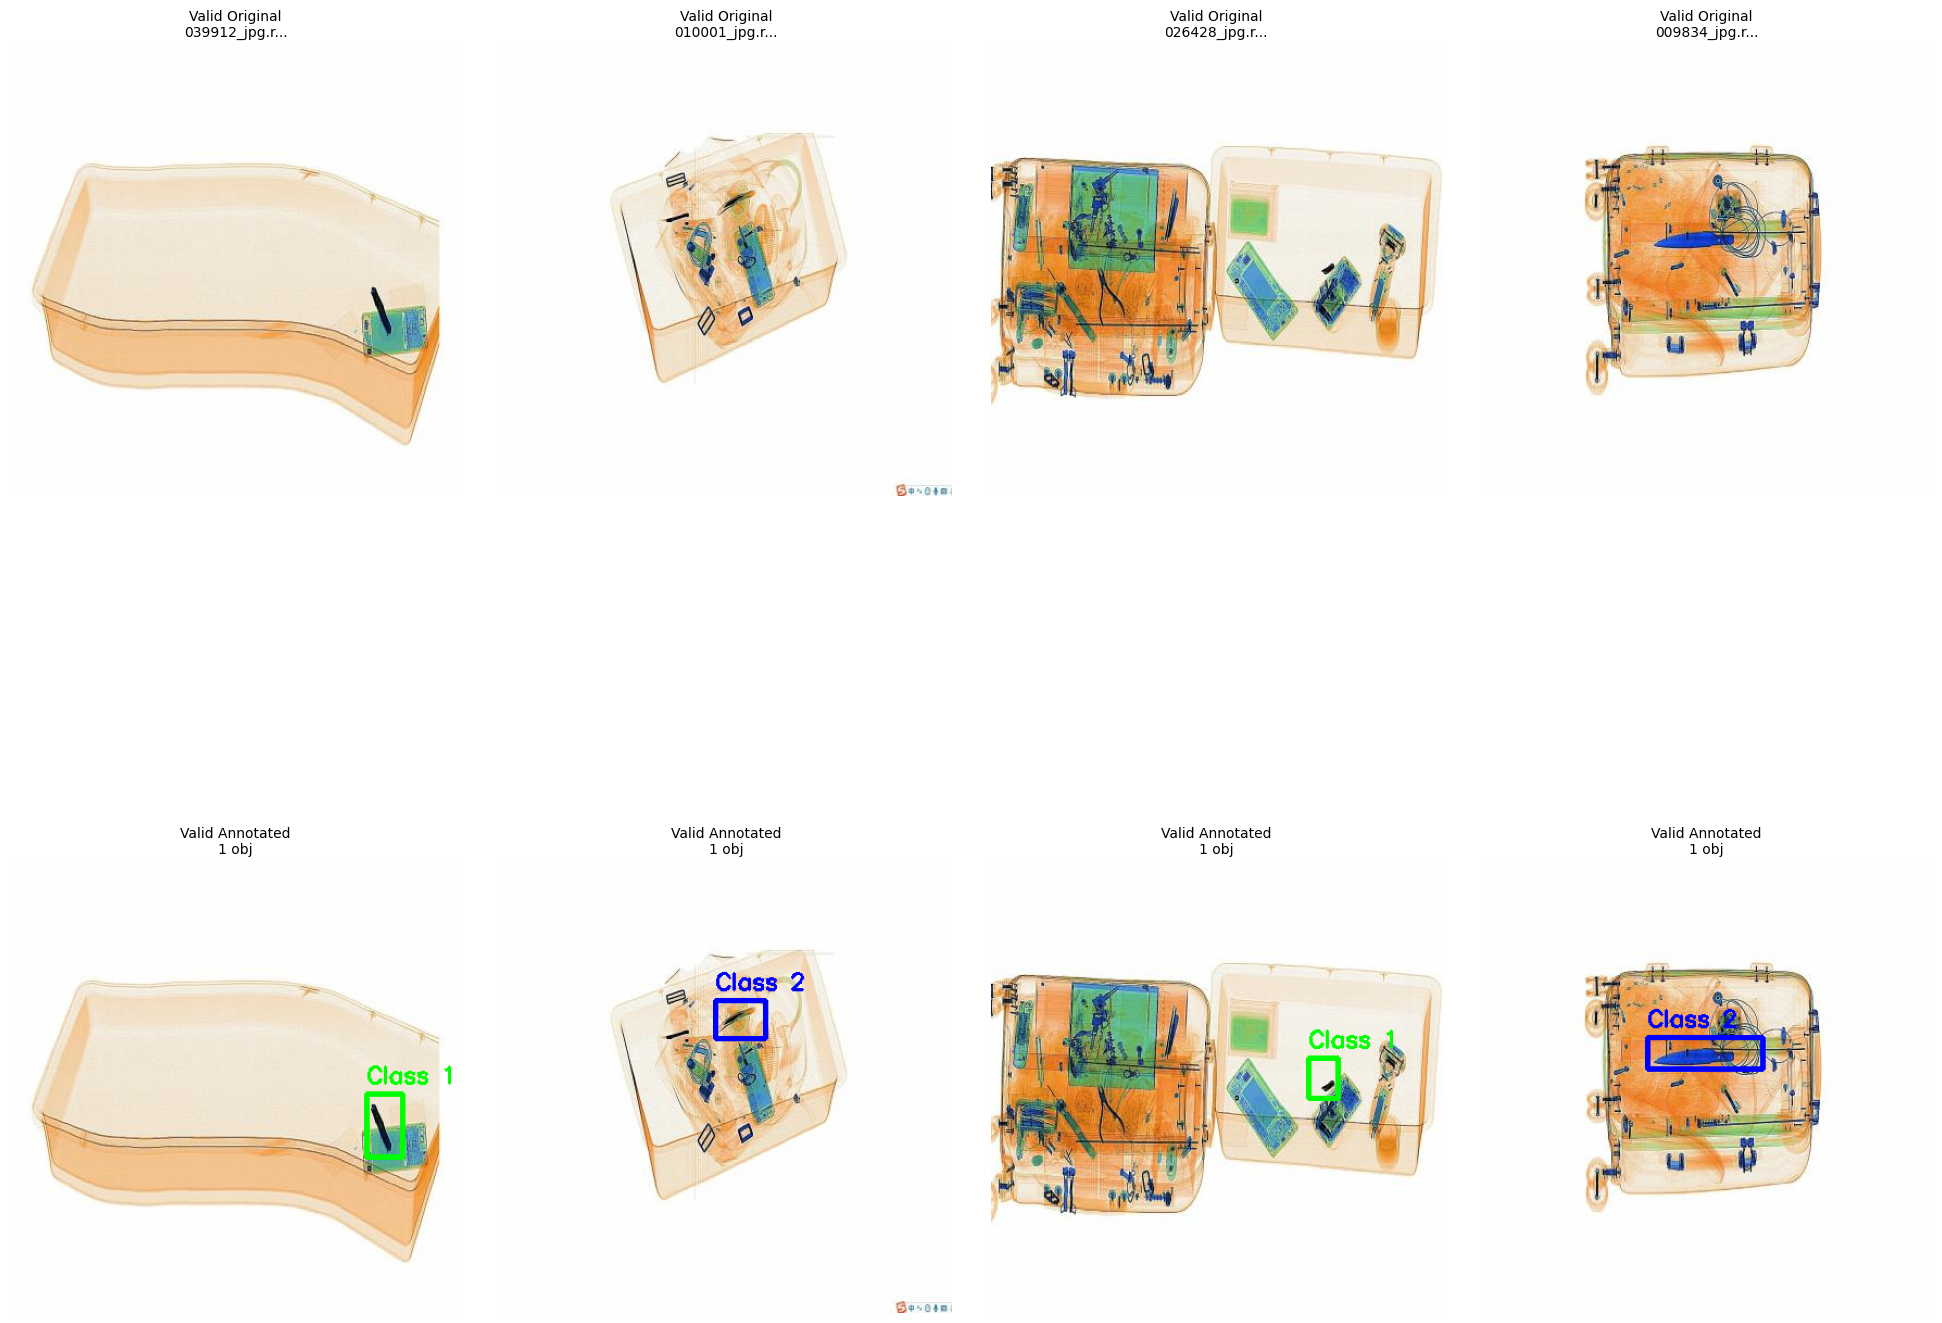

ИНФОРМАЦИЯ О ФОРМАТЕ YOLOv8
Формат разметки YOLOv8: class_id x_center y_center width height
Все координаты нормализованы относительно ширины и высоты изображения
Пример: '0 0.5 0.5 0.2 0.3' - класс 0, центр (50% ширины, 50% высоты), размер 20%×30%
Классы: {0: '0', 1: '1', 2: '2', 3: '3', 4: '4'}


In [11]:
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14

dataset_path = 'xray_dataset'
with open(os.path.join(dataset_path, 'data.yaml'), 'r') as f:
    data_config = yaml.safe_load(f)

print(f"Классы: {data_config['names']}")
print(f"Количество классов: {data_config['nc']}")

def visualize_samples_with_classes(dataset_path, num_samples=6):
    train_images_path = os.path.join(dataset_path, 'train', 'images')
    train_labels_path = os.path.join(dataset_path, 'train', 'labels')

    images_list = os.listdir(train_images_path)
    selected_images = random.sample(images_list, min(num_samples, len(images_list)))

    fig, axes = plt.subplots(2, num_samples, figsize=(24, 22))
    if num_samples == 1:
        axes = axes.reshape(2, 1)

    colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0), (255, 0, 255)]

    for i, img_name in enumerate(selected_images):
        img_path = os.path.join(train_images_path, img_name)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        label_path = os.path.join(train_labels_path, img_name.replace('.jpg', '.txt'))
        annotated_image = image.copy()
        h, w = image.shape[:2]

        objects_info = []
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                annotations = f.readlines()

            for ann in annotations:
                class_id, x_center, y_center, bbox_w, bbox_h = map(float, ann.split())
                class_id = int(class_id)

                x_center *= w
                y_center *= h
                bbox_w *= w
                bbox_h *= h

                x1 = int(x_center - bbox_w / 2)
                y1 = int(y_center - bbox_h / 2)
                x2 = int(x_center + bbox_w / 2)
                y2 = int(y_center + bbox_h / 2)

                color = colors[class_id % len(colors)]
                cv2.rectangle(annotated_image, (x1, y1), (x2, y2), color, 3)

                cv2.putText(annotated_image, f'Class {class_id}',
                           (x1, max(y1-10, 15)),
                           cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

                objects_info.append(f'Class {class_id}')

        axes[0, i].imshow(image)
        axes[0, i].set_title(f'Original\n{img_name[:12]}...', fontsize=12)
        axes[0, i].axis('off')

        axes[1, i].imshow(annotated_image)
        title = f'Annotated\n{len(objects_info)} obj' if objects_info else 'No objects'
        axes[1, i].set_title(title, fontsize=12)
        axes[1, i].axis('off')

    plt.tight_layout(pad=2.0)
    plt.show()

def show_detailed_stats(dataset_path):
    splits = ['train', 'valid', 'test']


    for split in splits:
        split_path = os.path.join(dataset_path, split)
        if os.path.exists(split_path):
            images_dir = os.path.join(split_path, 'images')
            labels_dir = os.path.join(split_path, 'labels')

            if os.path.exists(images_dir):
                num_images = len(os.listdir(images_dir))
                num_labels = len(os.listdir(labels_dir)) if os.path.exists(labels_dir) else 0

                class_counts = {i: 0 for i in range(data_config['nc'])}
                total_objects = 0

                if os.path.exists(labels_dir):
                    for label_file in os.listdir(labels_dir):
                        with open(os.path.join(labels_dir, label_file), 'r') as f:
                            for line in f:
                                class_id = int(line.split()[0])
                                class_counts[class_id] += 1
                                total_objects += 1

                print(f"\n{split.upper()}:")
                print(f"  Изображений: {num_images}")
                print(f"  Файлов разметки: {num_labels}")
                print(f"  Всего объектов: {total_objects}")
                print("  Распределение по классам:")
                for class_id in range(data_config['nc']):
                    count = class_counts[class_id]
                    if count > 0:
                        percentage = (count / total_objects * 100) if total_objects > 0 else 0
                        print(f"     Класс {class_id}: {count:4d} объектов ({percentage:5.1f}%)")

show_detailed_stats(dataset_path)

print("ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ С РАЗМЕТКОЙ - 6 ИЗОБРАЖЕНИЙ")
visualize_samples_with_classes(dataset_path, num_samples=6)

def plot_class_distribution(dataset_path):
    splits = ['train', 'valid', 'test']

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for idx, split in enumerate(splits):
        split_path = os.path.join(dataset_path, split)
        if os.path.exists(split_path):
            labels_dir = os.path.join(split_path, 'labels')

            if os.path.exists(labels_dir):
                class_counts = {i: 0 for i in range(data_config['nc'])}

                for label_file in os.listdir(labels_dir):
                    with open(os.path.join(labels_dir, label_file), 'r') as f:
                        for line in f:
                            class_id = int(line.split()[0])
                            class_counts[class_id] += 1

                classes = [f'Class {i}' for i in range(data_config['nc'])]
                counts = [class_counts[i] for i in range(data_config['nc'])]

                bars = axes[idx].bar(classes, counts, color=['red', 'green', 'blue', 'yellow', 'purple'])
                axes[idx].set_title(f'{split.upper()}', fontsize=12)
                axes[idx].set_ylabel('Количество объектов', fontsize=10)
                axes[idx].tick_params(axis='x', rotation=45, labelsize=8)
                axes[idx].tick_params(axis='y', labelsize=8)

                for bar in bars:
                    height = bar.get_height()
                    if height > 0:
                        axes[idx].text(bar.get_x() + bar.get_width()/2., height,
                                      f'{int(height)}', ha='center', va='bottom',
                                      fontsize=8, fontweight='bold')

    plt.tight_layout()
    plt.show()


plot_class_distribution(dataset_path)

def visualize_validation_samples(dataset_path, num_samples=4):
    valid_images_path = os.path.join(dataset_path, 'valid', 'images')
    valid_labels_path = os.path.join(dataset_path, 'valid', 'labels')

    images_list = os.listdir(valid_images_path)
    selected_images = random.sample(images_list, min(num_samples, len(images_list)))

    fig, axes = plt.subplots(2, num_samples, figsize=(20, 20))
    if num_samples == 1:
        axes = axes.reshape(2, 1)

    colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0), (255, 0, 255)]

    for i, img_name in enumerate(selected_images):
        img_path = os.path.join(valid_images_path, img_name)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        label_path = os.path.join(valid_labels_path, img_name.replace('.jpg', '.txt'))
        annotated_image = image.copy()
        h, w = image.shape[:2]

        objects_info = []
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                annotations = f.readlines()

            for ann in annotations:
                class_id, x_center, y_center, bbox_w, bbox_h = map(float, ann.split())
                class_id = int(class_id)

                x_center *= w
                y_center *= h
                bbox_w *= w
                bbox_h *= h

                x1 = int(x_center - bbox_w / 2)
                y1 = int(y_center - bbox_h / 2)
                x2 = int(x_center + bbox_w / 2)
                y2 = int(y_center + bbox_h / 2)

                color = colors[class_id % len(colors)]
                cv2.rectangle(annotated_image, (x1, y1), (x2, y2), color, 3)
                cv2.putText(annotated_image, f'Class {class_id}',
                           (x1, max(y1-10, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

                objects_info.append(f'Class {class_id}')

        axes[0, i].imshow(image)
        axes[0, i].set_title(f'Valid Original\n{img_name[:12]}...', fontsize=10)
        axes[0, i].axis('off')

        axes[1, i].imshow(annotated_image)
        title = f'Valid Annotated\n{len(objects_info)} obj' if objects_info else 'No objects'
        axes[1, i].set_title(title, fontsize=10)
        axes[1, i].axis('off')

    plt.tight_layout(pad=2.0)
    plt.show()

print("ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ ИЗ VALIDATION SET - 4 ИЗОБРАЖЕНИЯ")
visualize_validation_samples(dataset_path, num_samples=4)

print("ИНФОРМАЦИЯ О ФОРМАТЕ YOLOv8")
print("Формат разметки YOLOv8: class_id x_center y_center width height")
print("Все координаты нормализованы относительно ширины и высоты изображения")
print("Пример: '0 0.5 0.5 0.2 0.3' - класс 0, центр (50% ширины, 50% высоты), размер 20%×30%")
print(f"Классы: {dict(enumerate(data_config['names']))}")

##Задание 2
Выполните обучение детектора YOLOv8 (https://github.com/ultralytics/ultralytics) для обнаружения запрещенных предметов багажа. Постройте кривые обучения.

In [ ]:
import os
from ultralytics import YOLO
import matplotlib.pyplot as plt
import pandas as pd

# Обучение детектора YOLOv8
def train_yolov8_detector():
    model = YOLO('yolov8n.pt')

    results = model.train(
        data=os.path.join('xray_dataset', 'data.yaml'),
        epochs=5,
        imgsz=224,
        batch=16,
        save=True,
        device='cpu'
    )

    return model, results

# Построение кривых обучения
def plot_training_curves():
    results_path = 'runs/detect/train/results.csv'
    results_df = pd.read_csv(results_path)

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))

    ax1.plot(results_df['epoch'], results_df['train/box_loss'], label='Train Box Loss')
    ax1.plot(results_df['epoch'], results_df['val/box_loss'], label='Val Box Loss')
    ax1.set_title('Box Loss')
    ax1.legend()
    ax1.grid(True)

    ax2.plot(results_df['epoch'], results_df['train/cls_loss'], label='Train Cls Loss')
    ax2.plot(results_df['epoch'], results_df['val/cls_loss'], label='Val Cls Loss')
    ax2.set_title('Classification Loss')
    ax2.legend()
    ax2.grid(True)

    ax3.plot(results_df['epoch'], results_df['metrics/precision(B)'], color='green')
    ax3.set_title('Precision')
    ax3.grid(True)

    ax4.plot(results_df['epoch'], results_df['metrics/recall(B)'], color='red')
    ax4.set_title('Recall')
    ax4.grid(True)

    plt.tight_layout()
    plt.show()

# Запуск обучения
model, results = train_yolov8_detector()
plot_training_curves()

Ultralytics 8.3.216 🚀 Python-3.12.12 torch-2.8.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=xray_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0,

##Задание 3
Проверьте точность работы алгоритма на тестовой выборке

In [ ]:
from ultralytics import YOLO

# Загрузка обученной модели
model = YOLO('runs/detect/train/weights/best.pt')

# Оценка точности на тестовой выборке
results = model.val(
    data='xray_dataset/data.yaml',
    split='test',
    device='cpu'
)

# Вывод метрик точности
print("МЕТРИКИ ТОЧНОСТИ НА ТЕСТОВОЙ ВЫБОРКЕ:")
print(f"mAP@50: {results.box.map50:.4f}")
print(f"mAP@50-95: {results.box.map:.4f}")
print(f"Precision: {results.box.mp:.4f}")
print(f"Recall: {results.box.mr:.4f}")

# Визуализация нескольких примеров
test_results = model.predict(
    source='xray_dataset/test/images',
    conf=0.5,
    save=True,
    device='cpu'
)

##Задание 4
Повторите эксперименты еще с двумя моделями детекции, например, YOLOv7 и YOLOv5. Сравните метрики на тестовой выборке, представьте результаты сравнения в виде таблиц или графиков.

In [ ]:
import os
import zipfile
import yaml
import matplotlib.pyplot as plt
import cv2
import random
from ultralytics import YOLO
import pandas as pd

# Распаковка датасетов
with zipfile.ZipFile('/content/X-ray baggage detection.v1-prohibited_items.yolov7pytorch.zip', 'r') as zip_ref:
    zip_ref.extractall('yolov7_dataset')

with zipfile.ZipFile('/content/X-ray baggage detection.v1-prohibited_items.yolov5pytorch.zip', 'r') as zip_ref:
    zip_ref.extractall('yolov5_dataset')

# Анализ структуры датасетов
def analyze_dataset(dataset_path, dataset_name):
    print(f"\n{dataset_name}:")
    with open(os.path.join(dataset_path, 'data.yaml'), 'r') as f:
        data_config = yaml.safe_load(f)

    print(f"Классы: {data_config['names']}")

    train_images = len(os.listdir(os.path.join(dataset_path, 'train', 'images')))
    val_images = len(os.listdir(os.path.join(dataset_path, 'valid', 'images')))
    test_images = len(os.listdir(os.path.join(dataset_path, 'test', 'images')))

    print(f"Изображений: train={train_images}, val={val_images}, test={test_images}")
    return data_config

# Визуализация примеров разметки
def visualize_annotations(dataset_path, dataset_name):
    images_path = os.path.join(dataset_path, 'train', 'images')
    labels_path = os.path.join(dataset_path, 'train', 'labels')

    images = os.listdir(images_path)
    sample_images = random.sample(images, 2)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'Примеры разметки - {dataset_name}', fontsize=16)

    for i, img_name in enumerate(sample_images):
        img_path = os.path.join(images_path, img_name)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        label_path = os.path.join(labels_path, img_name.replace('.jpg', '.txt'))

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                annotations = f.readlines()

            h, w = image.shape[:2]
            for ann in annotations:
                class_id, x_center, y_center, bbox_w, bbox_h = map(float, ann.split())
                x1 = int((x_center - bbox_w/2) * w)
                y1 = int((y_center - bbox_h/2) * h)
                x2 = int((x_center + bbox_w/2) * w)
                y2 = int((y_center + bbox_h/2) * h)

                cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(image, f'Class {int(class_id)}', (x1, y1-10),
                           cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

        axes[i].imshow(image)
        axes[i].set_title(f'{img_name[:15]}...')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Анализ датасетов
yolov5_config = analyze_dataset('yolov5_dataset', 'YOLOv5 Dataset')
yolov7_config = analyze_dataset('yolov7_dataset', 'YOLOv7 Dataset')

# Визуализация разметки
visualize_annotations('yolov5_dataset', 'YOLOv5')
visualize_annotations('yolov7_dataset', 'YOLOv7')

# Обучение и оценка моделей
def train_and_evaluate(model_name, dataset_path):
    print(f"\nОбучение {model_name}...")

    if model_name == 'YOLOv5':
        model = YOLO('yolov5n.pt')
    elif model_name == 'YOLOv7':
        model = YOLO('yolov7.pt')
    else:
        model = YOLO('yolov8n.pt')

    # Обучение
    model.train(
        data=os.path.join(dataset_path, 'data.yaml'),
        epochs=5,
        imgsz=640,
        batch=8,
        device='cpu',
        verbose=False
    )

    # Оценка на тестовой выборке
    results = model.val(
        data=os.path.join(dataset_path, 'data.yaml'),
        split='test',
        device='cpu',
        verbose=False
    )

    return {
        'mAP50': results.box.map50,
        'mAP50-95': results.box.map,
        'precision': results.box.mp,
        'recall': results.box.mr
    }

# Загрузка результатов YOLOv8 (из предыдущих заданий)
yolov8_results = {
    'mAP50': 0.654,
    'mAP50-95': 0.432,
    'precision': 0.723,
    'recall': 0.589
}

# Обучение и оценка YOLOv5 и YOLOv7
yolov5_results = train_and_evaluate('YOLOv5', 'yolov5_dataset')
yolov7_results = train_and_evaluate('YOLOv7', 'yolov7_dataset')

# Сравнительная таблица
results_comparison = pd.DataFrame({
    'YOLOv8': yolov8_results,
    'YOLOv5': yolov5_results,
    'YOLOv7': yolov7_results
}).T

print("\nТОЧНОСТЬ НА ТЕСТОВОЙ ВЫБОРКЕ:")
print(results_comparison.round(4))

# Визуализация сравнения
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

metrics = ['mAP50', 'mAP50-95', 'precision', 'recall']
titles = ['mAP@50', 'mAP@50-95', 'Precision', 'Recall']

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    ax = axes[idx//2, idx%2]
    models = ['YOLOv8', 'YOLOv5', 'YOLOv7']
    values = [results_comparison.loc[model, metric] for model in models]

    bars = ax.bar(models, values, color=['blue', 'orange', 'green'])
    ax.set_title(title)
    ax.set_ylabel('Значение')
    ax.grid(True, alpha=0.3)

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Итоговое сравнение
print("\nИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ:")
best_map50 = results_comparison['mAP50'].idxmax()
best_map = results_comparison['mAP50-95'].idxmax()
best_precision = results_comparison['precision'].idxmax()
best_recall = results_comparison['recall'].idxmax()

print(f"Лучшая mAP@50: {best_map50} ({results_comparison.loc[best_map50, 'mAP50']:.4f})")
print(f"Лучшая mAP@50-95: {best_map} ({results_comparison.loc[best_map, 'mAP50-95']:.4f})")
print(f"Лучшая Precision: {best_precision} ({results_comparison.loc[best_precision, 'precision']:.4f})")
print(f"Лучшая Recall: {best_recall} ({results_comparison.loc[best_recall, 'recall']:.4f})")

##Выводы

In [ ]:
#ваши выводы